In [31]:
import numpy as np
from scipy import optimize
from dolfin import *
import matplotlib as mpl
import matplotlib.pyplot as plt
import os
from scipy.optimize import curve_fit
import pandas as pd
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
import yt
from numpy import inf
import sys
import json
from scipy.spatial import QhullError
import csv
import warnings
import glob
import math

def make_rings(data, ring_width):
    """
    Divide network into rings in the shape of the convex hull. Returns vertices of rings and radius for rings approximated as circles.
    data = (x,y) coordinates of network nodes and edges
    ring_width = width of rings
    """
    hull = ConvexHull(data)
    vertices0_index = hull.vertices
    vertices0_index = np.append(vertices0_index, vertices0_index[0])
    vertices0 = data[vertices0_index]

    rings = [vertices0]

    vertices_current = vertices0
    while Polygon(vertices_current).area > 0:
        # make rings
        buffer = shapely.buffer(Polygon(vertices_current), - ring_width).exterior.coords
        vertices_smaller = np.zeros(np.shape(vertices0))
        i = 0
        for x,y in buffer:
            vertices_smaller[i][0] = x
            vertices_smaller[i][1] = y
            i += 1
        vertices_current = vertices_smaller[~np.all(vertices_smaller == 0, axis=1)]
        rings.append(vertices_current)
    rings = rings[:-1] # remove last zero area polygon
    rings = rings[::-1]

    # make a few empty rings beyond the network (to improve sigmoid fit)
    for j in range(10):
        vertices_current = rings[-1]
        buffer = shapely.buffer(Polygon(vertices_current), + ring_width).exterior.coords
        vertices_bigger = []
        for x,y in buffer:
            vertices_bigger.append(np.array([x, y]))
        vertices_bigger = np.array(vertices_bigger)
        vertices_current = vertices_bigger[~np.all(vertices_bigger == 0, axis = 1)]
        rings.append(vertices_current)

    # get area of each ring and calculate radius of circle with that area
    r = []
    for ring in rings:
        area = Polygon(ring).area
        r.append(np.sqrt(area / np.pi)) 

    return rings, r

def sigmoid_t(t, K, L, tn):
    '''
    sigmoid function for fitting to filament density profile.
    t, K, L, tn = free parameters
    '''
    return K / (1 + np.exp(L * (tn - t)))

def sigmoid_r(r, K, L, r0, b):
    """
    sigmoid function with parameters L, r0, k, b. Fit to find wave front.
    """
    return K / (1 + np.exp(- L * (r0 - r))) + b

def gaussian(r, H, A, rn, s):
    """
    gaussian function with parameters H, A, xn, s. Fit to tip density in ring.
    """
    return H + A * np.exp(- (r - rn) ** 2 / (2 * s ** 2))

def prop_line(x, m):
    """
    line with 0 intercept. Fit to find average wave speed.
    """
    return m * x

def initial_pulse(r, A, s, r0):
    '''
    Gaussian function for fitting to initial pulse of tip density profile.
    r, A, s, r0 = free parameters
    '''
    return A * np.exp(-s * np.abs(r - r0) ** 2)

def tolerant_mean(arrs):
    '''
    Calculate mean of vectors with different length (e.g. data over different lengths of time, by only averaging over data that was collected for that time step).
    arrs = list of vectors to average
    '''
    lens = [len(i) for i in arrs]
    arr = np.ma.empty((np.max(lens),len(arrs)))
    arr.mask = True
    for idx, l in enumerate(arrs):
        arr[:len(l),idx] = l
    return arr.mean(axis = -1), arr.std(axis=-1)
    
def round_to_multiple(number, multiple):
    '''
    Round number to the nearest multiple of a number.
    number = number to round
    multiple = multiple of to round to
    '''
    return multiple * np.round(number / multiple)

def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

def density(data, rings):
    """
    Calculate density of points in each ring. Returns array with density in order starting from innermost ring.
    data = (x,y) coordinates of network nodes and edges
    rings = (x,y) coordinates of ring vertices (from function make_rings)
    """
    density = [0]

    for point in data:
        # inner most density is separate since it is not a ring
        if shapely.within(Point(point), Polygon(rings[0])):
            density[0] += 1
    density[0] /= Polygon(rings[0]).area

    j = 1        
    for ring in rings[1:]:
        # calculate density of each ring
        density.append(0)
        for point in data:
            if Polygon(ring).contains(Point(point)) and ~shapely.within(Point(point), Polygon(rings[j - 1])):
                density[j] += 1
        density[j] /= (Polygon(ring).area - Polygon(rings[j - 1]).area)
        j += 1

    return np.array(density)

def count(data, rings):
    """
    Count points in each ring. Returns array with count in order starting from innermost ring.
    data = (x,y) coordinates of network nodes and edges
    rings = (x,y) coordinates of ring vertices (from function make_rings)
    """
    count = [0]

    for point in data:
        # inner most density is separate since it is not a ring
        if shapely.within(Point(point), Polygon(rings[0])):
            count[0] += 1

    j = 1        
    for ring in rings[1:]:
        # calculate density of each ring
        count.append(0)
        for point in data:
            if Polygon(ring).contains(Point(point)) and ~shapely.within(Point(point), Polygon(rings[j - 1])):
                count[j] += 1
        j += 1

    return np.array(count)

def setup_fs_data(s_data, f_data, outf):
    '''
    Set up dataframes of number of split and fuse events at each hour/time step (for readin_data).
    s_data =  "splits.txt" listing the particle data id and time of split event (generated from simulation)
    f_data =  "fuses.txt" listing the particle data id and time of fuse event (generated from simulation)
    outf = final time step (e.g. 500000)
    '''
    s_data['split'] = 1 # 1 = yes split
    f_data['fuse'] = 1 # 1 = yes fuse
    # 1 simulation hour is 14400 time steps
    s_data['step_split'] = ((s_data['time_split'] / 0.25) / 400).round().astype(int) * 400
    f_data['step_fuse'] = ((f_data['time_fuse'] / 0.25) / 400).round().astype(int) * 400
    s_data['hour_split'] = (np.floor(s_data['time_split']) / (60 ** 2)).round().astype(int)
    f_data['hour_fuse'] = (np.floor(f_data['time_fuse']) / (60 ** 2)).round().astype(int)
    s_data['output_split'] = s_data['hour_split'] * 14400
    f_data['output_fuse'] = f_data['hour_fuse'] * 14400
    s_data = s_data[s_data['output_split'] < outf]
    f_data = f_data[f_data['output_fuse'] < outf]

    return s_data, f_data

def readin_data(run_name):
    '''
    Set up dataframes of particle position, count of split and fuse events.
    run_name = name of run used to label directory of data files (e.g. output_fungi_19_0)
    pdata_names = name to differentiate plt files from each time step (e.g. step number 14400, 28800...)
    outf = final time step (e.g. 500000)
    '''
    path =  '/Users/laurenyan/bmxfungi_surrogate/256_outputs/' + run_name + '/' # change to wherever the data are stored
    
    out_count = len(glob.glob1(path,"plt*")) - 1
    if out_count == 35:
        outf = 500000
    else:
        outf = 14400 * out_count
    out0 = 14400
    dout = 14400 # get data for each hour
    outs = np.arange(out0, outf, dout)
    pdata_names = [str(x) for x in outs]
    time = len(pdata_names) # hours
    pdata_all = {}

    # one file for each time step
    for i in range(len(pdata_names)):
        ds = yt.load(path + 'plt' + pdata_names[i])
        doi = ds.all_data()
        dfi = doi.to_dataframe([('all', 'particle_unique_id'), ('all', 'particle_position_x'), ('all', 'particle_position_y'), ('all', 'particle_position_z'), ('all', 'particle_position'),  ('all', 'particle_radius'), ('all', 'particle_cylinder_length'), ('all', 'particle_cell_volume')])
        dfi = dfi.rename(columns={'particle_unique_id': 'unique_id', 'particle_position_x': 'x', 'particle_position_y': 'y', 'particle_position_z': 'z', 'particle_position': 'position', 'particle_radius': 'radius', 'particle_cylinder_length': 'length', 'particle_cell_volume': 'volume'})

        pdata_all[int(pdata_names[i])] = dfi

    try:
        split_count = pd.read_csv(path + 'split_count.txt', names = ['count', 'time_split'])
        splits = pd.read_csv(path + 'splits.txt', names = ['unique_id', 'time_split'])
        fuse_count = pd.read_csv(path + 'fuse_count.txt', names = ['count', 'time_fuse'])
        fuses = pd.read_csv(path + 'fuses.txt', names = ['unique_id', 'time_fuse'])
    except FileNotFoundError:
        fuses = pd.DataFrame(columns=['unique_id', 'time_fuse'])
        fuse_count = pd.DataFrame(columns=['count', 'time_fuse'])
    splits, fuses = setup_fs_data(splits, fuses, outf)

    # data for all outputs where event occurs
    out_fs = pd.concat([fuses['output_fuse'], splits['output_split']]).unique()
    pdata_fs_names = [str(x) for x in out_fs if x != 0]
    pdata_fs = {}
    for i in range(len(pdata_fs_names)):
        ds = yt.load(path + 'plt' + pdata_fs_names[i])
        doi = ds.all_data()
        dfi = doi.to_dataframe([('all', 'particle_unique_id'), ('all', 'particle_position_x'), ('all', 'particle_position_y'), ('all', 'particle_position_z'), ('all', 'particle_position'),  ('all', 'particle_radius'), ('all', 'particle_cylinder_length')])
        dfi = dfi.rename(columns={'particle_unique_id': 'unique_id', 'particle_position_x': 'x', 'particle_position_y': 'y', 'particle_position_z': 'z', 'particle_position': 'position', 'particle_radius': 'radius', 'particle_cylinder_length': 'length'})
        pdata_fs[int(pdata_fs_names[i])] = dfi

    

    return pdata_all, pdata_fs, split_count, splits, fuse_count, fuses, time

def analyze_network(run_name, pdata_all, pdata_fs, fuses, splits, ring_width):
    """
    Plots network at final time, tip and filament density in time and space, position of wave front, and calculates mean speed of wave front. Also returns various constants related to these.
    run_name = name of run used to label directory of data files
    pdata_all = dictionary of dataframes of particle data (values) at each time step (keys) (from function readin_data)
    pdata_fs = dictionary of dataframes of particle data (values) at each time step that a split or fuse event occurs(keys) (from function readin_data)
    fuses = dataframes of number of fuse events at each hour/time step (from function setup_fs_data)
    splits = dataframes of number of splitevents at  each hour/time step (from function setup_fs_data)
    ring_width = width of rings
    """
    outf = list(pdata_all.keys())[-1]
    pdataf = pdata_all[outf]
    times = [int(t) * (0.25 / 3600) for t in pdata_all.keys()]
    rings, rs = make_rings(pdataf[['x','y']].to_numpy(), ring_width) # make rings from convex hull of final network shape
    n_rings = len(rings)
    density_tip_sum = {}
    density_in_sum = {}
    count_r = []
    tip_r = []
    in_r = []
    tip_t = []
    in_t = []
    ring_tip_t = []
    ring_in_t = []
    tns = []
    in_sat = []
    hr_f = int(times[-1]) # last output hour
    pdata_s = {}
    pdata_f = {}
    density_s_sum = {}
    density_f_sum = {}
    s_t = []
    f_t = []
    ring_s_t = []
    ring_f_t = []
    tip_pull_x = np.zeros(len(times))
    tip_pull_v = np.zeros(len(times))
    tip_all_x = np.zeros(len(times))
    tip_all_v = np.zeros(len(times))
    vdrift = np.zeros(len(times))
    xdrift = np.zeros(len(times))
    vdrift_pull = np.zeros(len(times))
    xdrift_pull = np.zeros(len(times))
    l_filament = 35

    for r in range(n_rings):
        tip_t.append({}) # one dictionary for each ring, will append density at each time
        in_t.append({})
        s_t.append({})
        f_t.append({})

    fig4, ax4 = plt.subplots(1, 3, figsize = (30,8))
    for ring in rings:
        ax4[0].plot(ring[:, 0], ring[:, 1], 'r--', lw = 1, alpha = 0.5)
        ax4[1].plot(ring[:, 0], ring[:, 1], 'r--', lw = 1, alpha = 0.5)
        ax4[2].plot(ring[:, 0], ring[:, 1], 'r--', lw = 1, alpha = 0.5)
    
    # network at final time step and origin of network
    pdataf = pdata_all[outf][['x', 'y']].to_numpy()
    hullf = ConvexHull(pdataf)
    tip_pull_i = hullf.vertices
    tip_pull_i = np.append(tip_pull_i, tip_pull_i[0])
    tip_pullf = pdataf[tip_pull_i]
    origin = shapely.centroid(Polygon(tip_pullf))
    x0 = origin.x
    y0 = origin.y


    # print(pdata_all[outf][['radius', 'length']])
    # pdata_all[outf][['radius', 'length']].hist(bins=3)
    
    i = 0
    u = 0
    for out in pdata_all.keys():
        time = int(out * (0.25 / 3600))

        # sorting out split and fusion data
        if out in pdata_fs.keys():
            pdata_fs_n = pdata_fs[out]

            if out in fuses['output_fuse'].values:
                fuses_out = fuses[fuses['output_fuse'] == out]
                pdata_fs_n = pdata_fs_n.merge(fuses_out, on = "unique_id", how = "left")
            else:
                pdata_fs_n['fuse'] = np.nan

            if out in splits['output_split'].values:
                splits_out = splits[splits['output_split'] == out]
                pdata_fs_n = pdata_fs_n.merge(splits_out, on = "unique_id", how = "left")
            else:
                pdata_fs_n['split'] = np.nan

            pdata_s[out] = pdata_fs_n[pdata_fs_n['split'] == 1] # particle data of all particles that split
            pdata_f[out] = pdata_fs_n[pdata_fs_n['fuse'] == 1] # particle data of all particles that fuse 

            # density in each ring
            density_s = density(pdata_s[out][['x','y']].to_numpy(), rings) # (hr-1cm-2)
            density_f = density(pdata_f[out][['x', 'y']].to_numpy(), rings) # (hr-1cm-2)
        else:
            density_s = [0] * n_rings
            density_f = [0] * n_rings

        q = 0
        for ring in rings:
            s_t[q][time] = density_s[q]
            f_t[q][time] = density_f[q]
            q += 1

        pdata = pdata_all[out]

        pdata = pdata[['x', 'y', 'position']]
        pdata_tip = pdata[pdata['position'] == 0]
        tip_all1 = pdata_tip[['x', 'y']].to_numpy()
        pdata_in = pdata[pdata['position'] != 0]
        pdata = pdata[['x', 'y']].to_numpy()

        # getting puller tips
        try:
            hull = ConvexHull(pdata)
            tip_pull_i = hull.vertices
            tip_pull_i = np.append(tip_pull_i, tip_pull_i[0])
            tip_pull1 = pdata[tip_pull_i]
        except QhullError as q:
            tip_pull1 = pdata

        # density in each ring
        density_tip = density(pdata_tip[['x','y']].to_numpy(), rings) # (hr-1cm-2)
        density_in = density(pdata_in[['x', 'y']].to_numpy(), rings) * l_filament # multiply number of edges by length of filament (umhr-1cm-2)
        tip_r.append(density_tip)
        in_r.append(density_in)

        count_r.append(count(pdata_tip[['x','y']].to_numpy(), rings))

        t0 = 5
        
        # ax4.plot(rings[np.argmax(pulse_max)][:, 0], rings[np.argmax(pulse_max)][:, 1], 'b--', lw = 1)
        if time == t0 or time == 17 or time == 34:
            ax4[u].scatter(pdata_tip['x'].to_numpy(), pdata_tip['y'].to_numpy(), color = 'slateblue', marker = 's')
            ax4[u].scatter(pdata_in['x'].to_numpy(), pdata_in['y'].to_numpy(), marker = 's', color = 'y')
            ax4[u].set_title(f'{time}hrs')
            ax4[u].set_xlabel('x(cm)')
            ax4[u].set_ylabel('y(cm)')
            u += 1
        
        k = 0
        for ring in rings:
            tip_t[k][time] = density_tip[k]
            in_t[k][time] = density_in[k]
            k += 1
            
        # displacement of puller tips from previous time step
        if i > 0: # can't calculate velocity in first time step
            j = 0
            for pull in tip_pull0:
                xtip = pull[0]
                ytip = pull[1]

                # velocity of puller tips
                distances = np.linalg.norm(tip_pull1 - pull, axis=1)
                min_index = np.argmin(distances)
                tip_pull_dx[j] = distances[min_index]

                # drift velocity of puller tips
                vtip = np.array([tip_pull1[min_index][0] - xtip, tip_pull1[min_index][1] - ytip])
                rtip = np.array([xtip-x0, ytip-y0])
                with warnings.catch_warnings():
                    warnings.filterwarnings("error", category=RuntimeWarning)
                    try:
                        theta = np.dot(rtip, vtip) / (np.linalg.norm(rtip) * np.linalg.norm(vtip))
                        vdrift_pull[i] += np.linalg.norm(vtip) * np.sin(theta) / 3600 # cm/s
                    except RuntimeWarning as r:                    
                        vdrift_pull[i] += 0 # cm/s
                        print(r)
                        print('tip velocity = ' + str(vtip))
                j += 1
            tip_pull_x[i] = tip_pull_x[i - 1] + np.mean(tip_pull_dx) # total displacement 
            tip_pull_v[i] = np.mean(tip_pull_dx) / 3600 # mean velocity over all tips cm/s
            vdrift_pull[i] /= len(tip_pull0)
            xdrift_pull[i] = xdrift_pull[i - 1] + vdrift_pull[i] * 3600 # cm

            j = 0
            for tip in tip_all0:
                xtip = tip[0]
                ytip = tip[1]

                # velocity of all tips
                distances = np.linalg.norm(tip_all1 - tip, axis=1)
                min_index = np.argmin(distances)
                tip_all_dx[j] = distances[min_index]

                # drift velocity of all tips
                vtip = np.array([tip_all1[min_index][0] - xtip, tip_all1[min_index][1] - ytip])
                rtip = np.array([xtip-x0, ytip-y0])
                with warnings.catch_warnings():
                    warnings.filterwarnings("error", category=RuntimeWarning)
                    try:
                        theta = np.dot(rtip, vtip) / (np.linalg.norm(rtip) * np.linalg.norm(vtip))
                        vdrift[i] += np.linalg.norm(vtip) * np.sin(theta) / 3600 # cm/s
                    except RuntimeWarning as r:                    
                        vdrift[i] += 0 # cm/s
                        print(r)
                        print('tip velocity = ' + str(vtip))
                j += 1
            tip_all_x[i] = tip_all_x[i - 1] + np.mean(tip_all_dx) # total displacement 
            tip_all_v[i] = np.mean(tip_all_dx) / 3600 # mean velocity over all tips cm/s
            vdrift[i] /= len(tip_all0)
            xdrift[i] = xdrift[i - 1] + vdrift[i] * 3600

        i += 1   
        tip_pull0 = tip_pull1 # saving tips to calculate velocity at next time
        tip_all0 = tip_all1
        tip_pull_dx = np.zeros(len(tip_pull0))
        tip_all_dx = np.zeros(len(tip_all0))
        
    pulse_max = max(tip_r[:][:3], key = max)
    A= np.max(pulse_max) / 100
    s= np.max(pulse_max)
    r0 = rs[np.argmax(pulse_max)]

    # in_r_f = tip_r[-1]
    # r0 = 0
    # for r in range(len(in_r_f)):
    #     if in_r_f[r0 + 1] > in_r_f[r0]:
    #         break
    #     else:
    #         r0 += 1

    

    r_t0 = np.argmax(tip_r[t0])
    if r_t0 > 0:
        r_t0 -= 1
    
    ax4[0].plot(rings[r_t0][:, 0], rings[r_t0][:, 1], 'b--', lw = 1) 
    ax4[1].plot(rings[r_t0][:, 0], rings[r_t0][:, 1], 'b--', lw = 1) 
    ax4[2].plot(rings[r_t0][:, 0], rings[r_t0][:, 1], 'b--', lw = 1) 

    # starting from center ring
    # try:
        # t0 = np.nonzero(np.array(list(tip_t[r0].values())))[0][0] # time when network "starts" at the center or smallest ring we want to measure from
    # except IndexError as i:
        # t0 = np.nonzero(np.array(list(tip_t[r0 + 1].values())))[0][0] # if the network never actually enters the center ring
        
    # fitting sigmoid curve to filament density over time of each ring
    in_t_fit = []
    omit_ring = [] # omit these rings for all averages over rings and with shifted time
    p = 0
    # fig19, ax19 = plt.subplots(1,2, figsize = (14, 7))
    for ring in in_t:
        try:
            ring_t = np.array(list(ring.values()))
            p0 = [np.max(ring_t), np.min(times), np.median(times)] # initial guess
            popt, pcov = curve_fit(sigmoid_t, times, ring_t, p0) # best fit parameters and covariance
            if popt[1] < 0:
                omit_ring.append(p)
                tns.append(0)
                # ax19[0].plot(times, sigmoid_t(times, popt[0], popt[1], popt[2]))
            else:
                if popt[2] > times[-1]:
                    tns.append(0)
                    # ax19[0].plot(times, sigmoid_t(times, popt[0], popt[1], popt[2]), 'r--')
                    # ax19[0].plot(times, ring_t, 'r', alpha = 0.3)
                    # ax19[0].vlines(popt[2], ymin = 0, ymax = np.max(ring_t), color ='r', alpha = 0.3, linestyle = '--')
                else:
                    tns.append(np.floor(popt[2]))
                    # ax19[1].plot(times, sigmoid_t(times, popt[0], popt[1], popt[2]), 'b--')
                    # ax19[1].plot(times, ring_t, 'b', alpha = 0.3)
                    # ax19[1].vlines(popt[2], ymin = 0, ymax = np.max(ring_t), alpha = 0.3, color = 'b', linestyle = '--')
                in_sat.append(popt[0])
                in_t_fit.append(sigmoid_t(times, popt[0], popt[1], popt[2]))
        
        except RuntimeError as e:
            omit_ring.append(p)
            tns.append(0)
        p += 1

    # tip_r_lines = [np.column_stack([rs[r0:], tip_r[p][r0:]]) for p in np.arange(0,int(times[-1]), 2)]
    # tip_r_lc = LineCollection(tip_r_lines, array = np.arange(0,int(times[-1]), 2), cmap = "plasma")
    # fig2, (ax2, ax3) = plt.subplots(1, 2, figsize = (16, 7))
    # ax2.add_collection(tip_r_lc)
    # ax2.set_xlim(rs[r0], rs[-1])
    # ax2.set_ylim(0, np.max(tip_r[-1]))
    # ax2.set_title('tip density in space')
    # ax2.set_xlabel(r'$r (cm)$')
    # ax2.set_ylabel(r'$n (cm^{-2})$')
    # fig2.colorbar(tip_r_lc, label="time", ax = ax3)
    # in_r_lines = [np.column_stack([rs[r0:], in_r[p][r0:]]) for p in np.arange(0,int(times[-1]), 2)]
    # in_r_lc = LineCollection(in_r_lines, array = np.arange(0,int(times[-1]), 2), cmap = "plasma")
    # # fig3, ax3 = plt.subplots()
    # ax3.add_collection(in_r_lc)
    # ax3.set_xlim(rs[r0], rs[-1])
    # ax3.set_ylim(0, np.max(in_r[-1]))
    # ax3.set_title('filament density in space')
    # ax3.set_xlabel(r'$r (cm)$')
    # ax3.set_ylabel(r'$\rho (\mu m cm^{-2})$')
    
    fig4.savefig('abm_output_ex.svg')

    r0 = 5
    shifted_t = np.arange(-int(times[-1] - tns[r0]), int(times[-1] - tns[r0]) + 1)

    # make dictionary with keys for shifted time
    for t in shifted_t:
        density_s_sum[t] = 0
        density_f_sum[t] = 0

    # calculating mean density of each ring at shifted time
    m = r0
    for ring_s, ring_f in zip(s_t[r0:], f_t[r0:]):
        if m not in omit_ring:
            tn = tns[m] # time to shift by
            ring_s_ti = []
            ring_f_ti = []
            for t in shifted_t:
                if t + tn in ring_s.keys():
                    density_s_sum[t] += ring_s[t + tn]
                    ring_s_ti.append(ring_s[t + tn])
                else:
                    density_s_sum[t] += 0 # no data for this time, so network has not arrived there yet
                    ring_s_ti.append(0)
                if t + tn in ring_f.keys():
                    density_f_sum[t] += ring_f[t + tn]
                    ring_f_ti.append(ring_f[t + tn])
                else:
                    density_f_sum[t] += 0
                    ring_f_ti.append(0)
            ring_s_t.append(ring_s_ti)
            ring_f_t.append(ring_f_ti)
        m += 1

    s_t_mean = [x / (n_rings - r0) for x in list(density_s_sum.values())]
    f_t_mean = [x / (n_rings - r0) for x in list(density_f_sum.values())]

    # make dictionary with keys for shifted time
    for t in shifted_t:
        density_tip_sum[t] = 0
        density_in_sum[t] = 0

    density_sat = []
    # calculating mean density of each ring at shifted time
    m = r0
    for ring_tip, ring_in in zip(tip_t[r0:], in_t[r0:]):
        if m not in omit_ring:
            tn = tns[m] # time to shift by
            ring_tip_ti = []
            ring_in_ti = []
            for t in shifted_t:
                if t + tn in ring_tip.keys():
                    density_tip_sum[t] += ring_tip[t + tn]
                    ring_tip_ti.append(ring_tip[t + tn])
                else:
                    density_tip_sum[t] += 0 # no data for this time, so network has not arrived there yet
                    ring_tip_ti.append(0)
                if t + tn in ring_in.keys():
                    density_in_sum[t] += ring_in[t + tn]
                    ring_in_ti.append(ring_in[t + tn])
                elif ((t + tn) > np.array(list(ring_in.keys()))).all(): # after the network passes through the ring the density is constant
                    density_in_sum[t] += ring_in[np.max(list(ring_in.keys()))]
                    ring_in_ti.append(ring_in[np.max(list(ring_in.keys()))])
                else:
                    density_in_sum[t] += 0
                    ring_in_ti.append(0)
            ring_tip_t.append(ring_tip_ti)
            ring_in_t.append(ring_in_ti)
        else:
            ring_tip_t.append(0)
            ring_in_t.append(0)

        ring_in_nonzero = np.array(list(ring_in.values()))[np.array(list(ring_in.values())) != 0]
        density_sat.append(np.median(ring_in_nonzero))
        
        m += 1

    tip_t_mean = [x / (n_rings - r0) for x in list(density_tip_sum.values())]
    in_t_mean = [x / (n_rings - r0) for x in list(density_in_sum.values())]

    # fig9, ax9 = plt.subplots()
    # ax9.plot(shifted_t, tip_t_mean)
    # ax9.set_title('mean tip density in time (n)')
    # ax9.set_xlabel(r'$t - t_{0} (hrs)$')
    # ax9.set_ylabel(r'$n (cm^{-2})$')
    # fig10, ax10 = plt.subplots()
    # ax10.plot(shifted_t, in_t_mean)
    # ax10.set_title(r'mean filament density in time ($\rho$)')
    # ax10.set_xlabel(r'$t - t_{0} (hrs)$')
    # ax10.set_ylabel(r'$\rho (\mu m cm^{-2})$')

    # fig30, ax30 = plt.subplots()
    # ax30.plot(shifted_t, s_t_mean)
    # ax30.set_title('mean splitting rate in time (b)')
    # ax30.set_xlabel(r'$t - t_{0} (hrs)$')
    # # ax30.set_ylabel(r'$n (cm^{-2})$')
    # fig31, ax31 = plt.subplots()
    # ax31.plot(shifted_t, f_t_mean)
    # ax31.set_title(r'mean fusion rate in time (a)')
    # ax31.set_xlabel(r'$t - t_{0} (hrs)$')
    # ax31.set_ylabel(r'$\rho (\mu m cm^{-2})$')
    
    # stop_plot = len(rs) - 5
    # norm = mpl.colors.Normalize(rs[r0], rs[stop_plot])
    # cmap = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.viridis)
    # fig7, (ax7, ax8) = plt.subplots(1, 2, figsize = (16, 7))
    # for l in range(r0, stop_plot):
    #     c = cmap.to_rgba(rs[l])
    #     ax7.plot(shifted_t, ring_tip_t[l], color = c)
    # ax7.set_xlim(shifted_t[0], shifted_t[-1])
    # ax7.set_ylim(0, np.max(ring_tip_t[r0][t0:]) + 1000)
    # ax7.set_title('tip density in time')
    # ax7.set_xlabel(r'$t - t_{0} (hrs)$')
    # ax7.set_ylabel(r'$n (cm^{-2})$')
    # for l in range(r0, stop_plot):
    #     c = cmap.to_rgba(rs[l])
    #     ax8.plot(shifted_t, ring_in_t[l], color = c)
    # ax8.set_xlim(shifted_t[0], shifted_t[-1])
    # ax8.set_ylim(0, np.max(ring_in_t[r0][t0:]) + 200)
    # ax8.set_title('filament density in time')
    # ax8.set_xlabel(r'$t - t_{0} (hrs)$')
    # ax8.set_ylabel(r'$n (cm^{-2})$')
    # fig7.colorbar(cmap, ticks=rs[r0:stop_plot], ax = ax8, label = 'radius')

    # stop_plot = len(rs) - 5
    # norm = mpl.colors.Normalize(rs[r0], rs[stop_plot])
    # cmap = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.viridis)
    # fig20, (ax20, ax21) = plt.subplots(1, 2, figsize = (16, 7))
    # for l in range(r0, stop_plot):
    #     c = cmap.to_rgba(rs[l])
    #     ax20.plot(shifted_t, ring_s_t[l], color = c)
    # ax20.set_xlim(shifted_t[0], shifted_t[-1])
    # ax20.set_ylim(0, np.max(ring_s_t[r0][t0:]) + 1000)
    # ax20.set_title('splitting rate in time')
    # ax20.set_xlabel(r'$t - t_{0} (hrs)$')
    # # ax20.set_ylabel(r'$n (cm^{-2})$')
    # for l in range(r0, stop_plot):
    #     c = cmap.to_rgba(rs[l])
    #     ax21.plot(shifted_t, ring_f_t[l], color = c)
    # ax21.set_xlim(shifted_t[0], shifted_t[-1])
    # ax21.set_ylim(0, np.max(ring_f_t[r0][t0:]) + 1000)
    # ax21.set_title('fusion rate in time')
    # ax21.set_xlabel(r'$t - t_{0} (hrs)$')
    # # ax21.set_ylabel(r'$n (cm^{-2})$')
    # fig20.colorbar(cmap, ticks=rs[r0:stop_plot], ax = ax21, label = 'radius')
    
    n = np.array(tip_t_mean)
    rho = np.array(in_t_mean)
    b = np.array(s_t_mean)
    a = np.array(f_t_mean)

    res = stats.linregress(times, xdrift) # cm/hr
    vd = res.slope * 10 # mm/hr
    sg = np.mean(tip_pull_v[1:]) * 36000 # mm/hr
    
    res = stats.linregress(n, b)
    alpha = res.slope
    alphan = n * alpha
    # fig11, ax11 = plt.subplots()
    # ax11.plot(shifted_t, alphan, label = r'$\alpha n$', color = 'b')
    # ax11.plot(shifted_t, b, label = '$b$', color = 'y')
    # ax11.legend(loc = "upper right")
    # ax_in1 = inset_axes(ax11, width="30%", height=2, loc="upper left")
    # ax_in1.plot(n, res.intercept + alpha * n, 'r', label='constant of proportionality')
    # ax_in1.scatter(n, b)
    # ax_in1.yaxis.tick_right()
    # ax_in1.yaxis.set_label_position("right")
    # ax_in1.set_xlabel(r'$n(cm^{-2})$')
    # ax_in1.set_ylabel(r'$b(hr^{-1}cm^{-2})$', ) 
    # ax11.set_title(rf'$b = {alpha:.2f} n$')
    # ax11.set_xlabel(r'$t - t_{0} (hrs)$')
    res = stats.linregress(n * rho, a)
    beta = res.slope
    betanrho = beta * n * rho
    nrho = n * rho
    # fig12, ax12 = plt.subplots()
    # ax12.plot(shifted_t, betanrho, label = r'$\beta n\rho$')
    # ax12.plot(shifted_t, a, label = '$a$')
    # ax12.legend(loc = "upper right")
    # ax_in2 = inset_axes(ax12, width="30%", height=2, loc="upper left")
    # ax_in2.plot(nrho, res.intercept + beta * nrho, 'r', label='constant of proportionality')
    # ax_in2.scatter(nrho, a)
    # ax_in2.yaxis.tick_right()
    # ax_in2.yaxis.set_label_position("right")
    # ax_in2.set_xlabel(r'$n\rho(\mu m cm^{-4})$')
    # ax_in2.set_ylabel(r'$a(hr^{-1}cm^{-2})$')
    # ax12.set_title(rf'$a = {beta * 1e8:.2f} n\rho$') # convert mum/cm to 1/mum
    # ax12.set_xlabel(r'$t - t_{0} (hrs)$')

    # fig13, ax13 = plt.subplots()
    # ax13.scatter(times[1:], vdrift_pull[1:], label = 'pulling tips')
    # ax13.scatter(times[1:], vdrift[1:])
    # res = stats.linregress(times, xdrift_pull)
    # ax_in4 = inset_axes(ax13, width="30%", height=2, loc="upper right")
    # ax_in4.scatter(times, xdrift_pull)
    # ax_in4.plot(times, np.array(times) * res.slope + res.intercept, 'r--')
    # ax_in4.set_xlabel('t(hrs)')
    # ax_in4.set_ylabel('r(cm)')
    # ax13.set_title('drift velocity = ' + f'{(res.slope / 3600):.1e}' + 'cm/s')
    # ax13.set_xlabel('t(hrs)')
    # ax13.set_ylabel(r'$v_{drift}(cm/s)$')
    # ax13.hlines(np.mean(vdrift[1:]), xmin = times[0], xmax = times[-1], color = 'g')
    # ax13.legend()

    # fig14, ax14 = plt.subplots()
    # ax14.scatter(rs[r0:stop_plot], density_sat[:stop_plot-r0]) 
    # ax14.hlines(2 * alpha / beta, xmin = rs[r0], xmax = rs[-1], color = 'r', linestyle='--', label = r'$\frac{2\alpha}{\beta} = $' + f'{2 * 1e-8 * alpha / beta:.5f}')
    # ax14.legend(loc = 'lower left')
    # ax14.set_xlim(rs[r0-1], rs[stop_plot+1])

    # t0 = 3

    return tip_r, in_r, tip_t, in_t, ring_tip_t, ring_in_t, ring_s_t, ring_f_t, tip_t_mean, in_t_mean, s_t_mean, f_t_mean, xdrift[t0:], xdrift_pull[t0:], rs, r0, t0, shifted_t, alpha, beta, vd, sg, omit_ring, r_t0

def density_c(tip_r, in_r, tip_t, in_t, rs, r0, t0, tf, r_t0):
    '''
    Calculates maximum tip density, median filament density and wavefront position at each time step and maximum tip density and median filament density position over time.
    tip_r = dictionary of tip density profile in space (values) at each time step (keys) (from function analyze_network)
    in_r = dictionary of filament density in space (values) at each time step (keys) (from function analyze_network)
    tip_t = list of dictionaries for each ring of tip density (values) at each time step (keys) (from function analyze_network)
    in_t = list of dictionaries for each ring of filament density (values) at each time step (keys) (from function analyze_network)
    rs = radius of each ring (from function make_rings)
    tf = length of simulation in hours
    r0 = radius of ring to start from (if wanting to omit some inner rings)
    t0 = time to start from (if wanting to omit some initial time)
    '''
    times = np.arange(t0, tf)
    n_sat_t = []
    rho_sat_t = []
    wavefront_in_t = []
    wavefront_tip_t = []
    n_sat_r = []
    rho_sat_r = []

    k = 0
    for r in rs:
        tip_t_r = np.array(list(tip_t[k].values()))
        in_t_r = np.array(in_r[np.argmax(tip_t_r)])
        n_sat_r.append(np.max(tip_t_r))
        rho_sat_r.append(np.median(in_t_r[in_t_r != 0]))
        k += 1

    cmap = mpl.colormaps["winter"]
    cmap2 = mpl.colormaps["spring"]
    
    fig87, ax87 = plt.subplots(1, len(times), figsize = (3 * len(times), 3))
    fig88, ax88 = plt.subplots(1, len(times), figsize = (3 * len(times), 3))
    
    r_eq = rs[r0:]
    l = 0
    for t in times:
        in_r_t = np.array(in_r[t][r0:])
        tip_r_t = np.array(tip_r[t][r0:])
        n_sat_t.append(np.max(tip_r_t))
        rho_sat = np.median(in_r_t[in_r_t != 0])
        rho_sat_t.append(rho_sat)

        ax87[l].scatter(r_eq, in_r_t, color = cmap(t/times[-1]), marker = '.')
        ax88[l].scatter(r_eq, tip_r_t, color = cmap(t/times[-1]), marker = '.')

        in_cs = CubicSpline(r_eq, in_r_t)
        ax87[l].plot(r_eq, in_cs(r_eq), color = cmap2(t/times[-1]), linestyle = ':')
        tip_cs = CubicSpline(r_eq, tip_r_t)
        ax88[l].plot(r_eq, tip_cs(r_eq), color = cmap2(t/times[-1]), linestyle = ':')

        try:
            p0 = [rho_sat, - np.median(r_eq), np.median(r_eq), 0] # initial guess
            popt, pcov = curve_fit(sigmoid_r, r_eq, in_r_t, p0, maxfev = 5000)
            ax87[l].plot(r_eq, sigmoid_r(r_eq, popt[0], popt[1], popt[2], popt[3]), color = 'y')
        except RuntimeError as e:
            print('no sigmoid fit')

        # half_maxs = in_cs.solve(y = rho_sat / 2)
        # r_front = np.max(half_maxs)
        # wavefront = r_eq[find_nearest(r_eq, r_front)]
        # ax87[l].plot(wavefront, rho_sat / 2, marker = '*', color = 'tab:orange')
        try:
            half_maxs = in_cs.solve(y = rho_sat / 2)
            if len(wavefront_in_t) > 1:
                wavefront_in = np.max(half_maxs[(half_maxs >= wavefront_in_t[-1]) & (half_maxs <= np.max(r_eq))])
            else:
                wavefront_in = np.max(half_maxs[half_maxs <= np.max(r_eq)])
            ax87[l].plot(wavefront_in, rho_sat / 2, marker = '*', color = 'k')
        except ValueError as v:
            wavefront_in = np.max(half_maxs[half_maxs <= np.max(r_eq)])
            ax87[l].plot(wavefront_in, rho_sat / 2, marker = 'x', color = 'k')
        
       
        wavefront_tip = r_eq[np.argmax(tip_r_t)]
        tip_max = np.max(tip_r_t)
        max_i = np.argmax(tip_r_t)
        if len(wavefront_tip_t) > 0:
            while wavefront_tip < wavefront_tip_t[-1]:
                if wavefront_tip > r_eq[-1]:
                    wavefront_tip = r_eq[-1]
                    break
                max_i = np.argmax(tip_r_t[max_i + 1:]) + max_i + 1
                wavefront_tip = r_eq[max_i]
                tip_max = np.max(tip_r_t[max_i + 1:])
        ax88[l].plot(wavefront_tip, tip_max, marker = '*', color = 'k')
            # wavefront = popt[2]
            # ax87[l].plot(wavefront, sigmoid_r(wavefront, popt[0], popt[1], popt[2], popt[3]), marker = '*', color = 'tab:orange')
        
        # except IndexError as e:
            # print(np.argmax(tip_r_t))
            # print(r_eq[np.argmax(tip_r_t)])
            # wavefront_tip = r_eq[0]
            # ax88[l].plot(wavefront_tip, np.max(tip_r_t), marker = 'x', color = 'k')
        
        wavefront_in_t.append(wavefront_in)
        wavefront_tip_t.append(wavefront_tip)

        l += 1
    return np.array(n_sat_t), np.array(rho_sat_t), np.array(n_sat_r), np.array(rho_sat_r), np.array(wavefront_in_t), np.array(wavefront_tip_t)

In [65]:
def ABM(sim_name, n_runs, ring_width):
    '''
    Makes final ABM output. Takes average and standard deviation of density and wavefront position data over multiple replicate runs and estimates PDE constant values.
    sim_name = name of simulation used to label set of directories of replicate data files (e.g. output_fungi_19 for output_fungi_19_0, output_fungi_19_1, and output_fungi_19_2)
    n_runs = number of replicates (e.g. 3)
    outf = final time step (e.g. 500000) 
    '''
    tip_rs = []
    in_rs = []
    tip_ts = []
    in_ts = []
    ring_tip_ts = []
    ring_in_ts = []
    ring_s_ts = []
    ring_f_ts = []
    ring_tip_t_means = []
    ring_in_t_means = []
    ring_s_t_means = []
    ring_f_t_means = []
    omit_rings = []
    n_maxs_t = []
    rho_maxs_t = []
    n_maxs_r = []
    rho_maxs_r = []
    wavefronts_in = []
    wavefronts_tip = []
    xdrifts = []
    xdrift_pulls = []
    # wavefronts_slope = []
    xdrifts_slope = []
    xdrift_pulls_slope = []
    # wavefronts_intercept = []
    xdrifts_intercept = []
    xdrift_pulls_intercept = []
    r_max = []
    t0min = 35
    tfmax = 0
    shifted_t_min = range(100)
    
    for i in range(n_runs):
        
        run_name = sim_name + '_' + str(i)
        datai, data_fsi, split_counti, splitsi, fuse_counti, fusesi, tfi = readin_data(run_name)
        outputi = analyze_network(run_name, datai, data_fsi, fusesi, splitsi, ring_width)
        # tip_r, in_r, tip_t, in_t, ring_tip_t, ring_in_t, ring_s_t, ring_f_t, tip_t_mean, in_t_mean, s_t_mean, f_t_mean, xdrift, xdrift_pull, rs, r0, t0, shifted_t, alpha, beta, vd, sg, omit_ring
        tip_rs.append(outputi[0])
        in_rs.append(outputi[1])
        tip_ts.append(outputi[2])
        in_ts.append(outputi[3])
        ring_tip_ts.append(outputi[4])
        ring_in_ts.append(outputi[5])
        ring_s_ts.append(outputi[6])
        ring_f_ts.append(outputi[7])
        ring_tip_t_means.append(outputi[8])
        ring_in_t_means.append(outputi[9])
        ring_s_t_means.append(outputi[10])
        ring_f_t_means.append(outputi[11])
        rs = outputi[14]
        r0i = outputi[15]
        t0i = outputi[16]
        r_t0i = outputi[23]
        shifted_t = outputi[17]
        omit_rings += outputi[22]
        
        print(run_name + ':')
        print('starting at time = ' + str(t0i) + ' and ring = ' + str(r0i))

        nm_t, rm_t, nm_r, rm_r, wf_in, wf_tip = density_c(outputi[0], outputi[1], outputi[2], outputi[3], rs, r0i, t0i, tfi, r_t0i)
        nm_t /= 100
        rm_t *= 1e-5
        nm_r /= 100
        rm_r *= 1e-5
        # wf_in -= 0.0025
        wf_in *= 10
        wf_in -= wf_in[0]
        # wf_tip -= 0.0025
        wf_tip *= 10
        wf_tip -= wf_tip[0]
        xd = np.array(outputi[12]) * 10
        xd -= xd[0]
        xd_pull = np.array(outputi[13]) * 10
        xd_pull -= xd_pull[0]
        n_maxs_t.append(nm_t)
        rho_maxs_t.append(rm_t)
        n_maxs_r.append(nm_r)
        rho_maxs_r.append(rm_r)
        wavefronts_in.append(wf_in)
        wavefronts_tip.append(wf_tip)
        xdrifts.append(xd)
        xdrift_pulls.append(xd_pull)

        # calculate wave speed
        times = np.arange(t0i, tfi) - t0i
        # res = stats.linregress(times, wf)
        # wavefronts_slope.append(res.slope)
        # wavefronts_intercept.append(res.intercept)
        res = stats.linregress(times, xd_pull)
        xdrift_pulls_slope.append(res.slope)
        xdrift_pulls_intercept.append(res.intercept)
        res = stats.linregress(times, xd)
        xdrifts_slope.append(res.slope)
        xdrifts_intercept.append(res.intercept)
        

        if len(rs) > len(r_max):
            r_max = rs
        if len(shifted_t) < len(shifted_t_min):
            shifted_t_min = shifted_t
        if tfi > tfmax:
            tfmax = tfi
        if t0i < t0min:
            t0min = t0i

        # r_df = pd.DataFrame({'r(cm)': rs})
        
        # for t in range(time):
            # r_df['n at hour ' + str(t) + ' (cm^-2)'] = outputi[0][t]
            # r_df['rho at hour ' + str(t) + ' (cm^-2)'] = outputi[1][t]

        # r_df.to_csv(run_name + '_wavespace.csv', index=False)
        i += 1
    
    times = np.arange(t0min, tfmax) - t0min
    tip_r_mean = []
    tip_r_std = []
    in_r_mean = []
    in_r_std = []
    # r_df = pd.DataFrame({'r(cm)': r_max})
    for t in range(tfi):
        tip_t = []
        in_t = []
        for n in range(n_runs):
            tip_t.append(tip_rs[n][t])
            in_t.append(in_rs[n][t])
        tip_r_mean.append(tolerant_mean(tip_t)[0])
        tip_r_std.append(tolerant_mean(tip_t)[1])
        in_r_mean.append(tolerant_mean(in_t)[0])
        in_r_std.append(tolerant_mean(in_t)[1])
        # r_df['n at hour ' + str(t) + ' (cm^-2)'] = tolerant_mean(tip_t)[0]
        # r_df['rho at hour ' + str(t) + ' (cm^-2)'] = tolerant_mean(in_t)[0]
    # r_df.to_csv(sim_name + '_wavespace.csv', index=False)
    
    cutoff = 1
    # fig7, (ax7, ax8) = plt.subplots(1, 2, figsize = (16, 7))
    tip_rs_all = []
    in_rs_all = []
    tip_rs_all2 = []
    in_rs_all2 = []
    for n in range(n_runs):
        ring_tips = ring_tip_ts[n]
        ring_ins = ring_in_ts[n]
        ring_tip_mean = ring_tip_t_means[n]
        ring_in_mean = ring_in_t_means[n]
        while len(ring_tip_mean) > len(shifted_t_min):
            ring_tip_mean = ring_tip_mean[1:-1]
        while len(ring_in_mean) > len(shifted_t_min):
            ring_in_mean = ring_in_mean[1:-1]
        for ring_tip, ring_in in zip(ring_tips, ring_ins):
            if ring_tip != 0:
                while len(ring_tip) > len(shifted_t_min):
                    ring_tip = ring_tip[1:-1]
                while len(ring_in) > len(shifted_t_min):
                    ring_in = ring_in[1:-1]
                tip_rs_all.append(ring_tip)
                in_rs_all.append(ring_in)
        tip_rs_all2.append(ring_tip_mean)
        in_rs_all2.append(ring_in_mean)
        # ax7.plot(shifted_t_min[cutoff:-cutoff],  ring_tip_mean[cutoff:-cutoff])
        # ax8.plot(shifted_t_min[cutoff:-cutoff],  ring_in_mean[cutoff:-cutoff])

    r0 = r0i
    rings_tip_mean = []
    rings_in_mean = []
    for r in range(r0, len(r_max) - r0):
        r_tip = []
        r_in = []
        for n in range(n_runs):
            if r < len(ring_tip_ts[n]):
                ring_tip = ring_tip_ts[n][r]
                ring_in = ring_in_ts[n][r]
                if ring_tip != 0:
                    while len(ring_tip) > len(shifted_t_min):
                        ring_tip = ring_tip[1:-1]
                    while len(ring_in) > len(shifted_t_min):
                        ring_in = ring_in[1:-1]
                    r_tip.append(ring_tip)
                    r_in.append(ring_in)
        if len(r_tip) > 0:
            rings_tip_mean.append(np.mean(np.vstack(r_tip), axis = 0))
            rings_in_mean.append(np.mean(np.vstack(r_in), axis = 0))
    
                
    # t_df = pd.DataFrame({'shifted t(hrs)': shifted_t_min[cutoff:-cutoff]})
    # method 1 mean of all
    # ring_tip_t_mean = np.mean(np.vstack(tip_rs_all), axis = 0)
    # ring_in_t_mean = np.mean(np.vstack(in_rs_all), axis = 0)
    # ring_tip_t_std = np.std(np.vstack(tip_rs_all), axis = 0)
    # ring_in_t_std = np.std(np.vstack(in_rs_all), axis = 0)
    # method 2 mean of means
    ring_tip_t_mean2 = np.mean(np.vstack(tip_rs_all2), axis = 0)
    ring_in_t_mean2 = np.mean(np.vstack(in_rs_all2), axis = 0)
    ring_tip_t_std2 = np.std(np.vstack(tip_rs_all2), axis = 0)
    ring_in_t_std2 = np.std(np.vstack(in_rs_all2), axis = 0)
    # t_df['n in ring reference frame (cm^-2)'] = ring_tip_t_mean[cutoff:-cutoff]
    # t_df['rho in ring reference frame (cm^-2)'] = ring_in_t_mean[cutoff:-cutoff]
    # t_df.to_csv(sim_name + '_wavetime.csv', index=False)

    wf_in_mean = tolerant_mean(wavefronts_in)[0]
    wf_tip_mean = tolerant_mean(wavefronts_tip)[0]
    xd_mean = tolerant_mean(xdrifts)[0]
    xd_pull_mean = tolerant_mean(xdrift_pulls)[0]
    
    # fig13, (ax13, ax14) = plt.subplots(1, 2, figsize = (16, 7))
    s_rs_all = []
    f_rs_all = []
    s_rs_all2 = []
    f_rs_all2 = []
    for n in range(n_runs):
        ring_ss = ring_s_ts[n]
        ring_fs = ring_f_ts[n]
        ring_s_mean = ring_s_t_means[n]
        ring_f_mean = ring_f_t_means[n]
        while len(ring_f_mean) > len(shifted_t_min):
            ring_f_mean = ring_f_mean[1:-1]
        while len(ring_s_mean) > len(shifted_t_min):
            ring_s_mean = ring_s_mean[1:-1]
        for ring_s, ring_f in zip(ring_ss, ring_fs):
            while len(ring_s) > len(shifted_t_min):
                ring_s = ring_s[1:-1]
            while len(ring_f) > len(shifted_t_min):
                ring_f = ring_f[1:-1]
            s_rs_all.append(ring_s) 
            f_rs_all.append(ring_f)
        s_rs_all2.append(ring_s_mean) 
        f_rs_all2.append(ring_f_mean)
        # ax13.plot(shifted_t_min[cutoff:-cutoff],  ring_s_mean[cutoff:-cutoff])
        # ax14.plot(shifted_t_min[cutoff:-cutoff],  ring_f_mean[cutoff:-cutoff])          
    # ring_s_t_mean = np.mean(np.vstack(s_rs_all), axis = 0)
    # ring_f_t_mean = np.mean(np.vstack(f_rs_all), axis = 0)
    # ring_s_t_std = np.std(np.vstack(s_rs_all), axis = 0)
    # ring_f_t_std = np.std(np.vstack(f_rs_all), axis = 0)
    
    ring_s_t_mean2 = np.mean(np.vstack(s_rs_all2), axis = 0)
    ring_f_t_mean2 = np.mean(np.vstack(f_rs_all2), axis = 0)
    ring_s_t_std2 = np.std(np.vstack(s_rs_all2), axis = 0)
    ring_f_t_std2 = np.std(np.vstack(f_rs_all2), axis = 0)

    tip_r_lines = [np.column_stack([r_max[r0:], tip_r_mean[p][r0:]]) for p in np.arange(0,int(times[-1]), 2)]
    tip_r_lc = LineCollection(tip_r_lines, array = np.arange(0,int(times[-1]), 4), cmap = "plasma", linewidths=2)
    fig20, axs20 = plt.subplots(2, 1, figsize = (7, 12), sharex=True)
    axs20[0].add_collection(tip_r_lc)
    axs20[0].set_xlim(r_max[r0], r_max[-1])
    axs20[0].set_ylim(0, 7000)
    axs20[0].set_title('tip density in space')
    # ax20.set_xlabel(r'$r (cm)$')
    axs20[0].set_ylabel(r'$n (cm^{-2})$')
    fig20.colorbar(tip_r_lc, label="t(hrs)", ax = axs20, shrink = 0.6)
    in_r_lines = [np.column_stack([r_max[r0:], in_r_mean[p][r0:]]) for p in np.arange(0,int(times[-1]), 2)]
    in_r_lc = LineCollection(in_r_lines, array = np.arange(0,int(times[-1]), 4), cmap = "plasma", linewidths=2)
    axs20[1].add_collection(in_r_lc)
    axs20[1].set_xlim(r_max[r0], r_max[-1])
    axs20[1].set_ylim(0, 1.2 * 1e6)
    axs20[1].set_title('filament density in space')
    axs20[1].set_xlabel(r'$r(cm)$')
    axs20[1].set_ylabel(r'$\rho (\mu m cm^{-2})$')
    fig20.savefig('waveprofile_ex.svg')
    # tip_t_lines = [np.column_stack([shifted_t_min, rings_tip_mean[p]]) for p in np.arange(0,len(rings_tip_mean) - 2)]
    # tip_t_lc = LineCollection(tip_t_lines, array = r_max[r0:len(rings_tip_mean) - (2 + r0)], cmap = "viridis")
    # fig40, axs40 = plt.subplots(2, 1, figsize = (7, 12), sharex=True)
    # axs40[0].add_collection(tip_t_lc)
    # axs40[0].set_xlim(shifted_t_min[0], shifted_t_min[-1])
    # axs40[0].set_ylim(0, np.max(rings_tip_mean) * 1.1)
    # axs40[0].set_title('tip density in time')
    # # ax20.set_xlabel(r'$r (cm)$')
    # axs40[0].set_ylabel(r'$n (cm^{-2})$')
    # fig40.colorbar(tip_t_lc, label="r(cm)", ax = axs40, shrink = 0.6)
    # in_t_lines = [np.column_stack([shifted_t_min, rings_in_mean[p]]) for p in np.arange(0,len(rings_tip_mean) - 2)]
    # in_t_lc = LineCollection(in_t_lines, array = r_max[r0:len(rings_tip_mean) - (2 + r0)], cmap = "viridis")
    # axs40[1].add_collection(in_t_lc)
    # axs40[1].set_xlim(shifted_t_min[0], shifted_t_min[-1])
    # axs40[1].set_ylim(0, np.max(rings_in_mean) * 1.1)
    # axs40[1].set_title('filament density in time')
    # axs40[1].set_xlabel(r'$t - t_0(hrs)$')
    # axs40[1].set_ylabel(r'$\rho(\mu m cm^{-2})$')

    n = np.array(ring_tip_t_mean2) / 100
    n_std = np.array(ring_tip_t_std2) / 100
    rho = np.array(ring_in_t_mean2) * 1e-5
    rho_std = np.array(ring_in_t_std2) * 1e-5
    b  = np.array(ring_s_t_mean2) / 100
    b_std  = np.array(ring_s_t_std2) / 100
    a = np.array(ring_f_t_mean2) / 100
    a_std = np.array(ring_f_t_std2) / 100

    n_cs = CubicSpline(shifted_t_min, n)
    rho_cs = CubicSpline(shifted_t_min, rho)

    N = np.max(n)
    L_eff = n_cs.solve(y = N / math.e)[-1]
    xf = shifted_t_min[np.nonzero(n)[0][-1]]
   
    fig50, ax50 = plt.subplots()
    ax50.plot(shifted_t_min, n, label = r'$n$')
    ax50.vlines(L_eff, 0, N, color = 'tab:orange', linestyle = '--')
    ax50.vlines(xf, 0, N, color = 'tab:orange', linestyle = '--')

    N_eff = n_cs.integrate(L_eff, xf)
    
    # fig40, axs40 = plt.subplots(2, 1, figsize = (7, 12), sharex=True)
    # for n_t in tip_rs_all:
    #     axs40[0].scatter(shifted_t_min, n_t, color = 'xkcd:soft green')
    # for rho_t in in_rs_all:
    #     axs40[1].scatter(shifted_t_min, rho_t, color = 'xkcd:soft green')
    # axs40[0].plot(shifted_t_min, density_tip_cs(shifted_t_min))
    # # axs40[1].plot(shifted_t_min, rho)
    # axs40[1].plot(shifted_t_min, density_in_cs(shifted_t_min))
    # axs40[1].set_xlim(shifted_t_min[0], shifted_t_min[-1])
    # axs40[1].set_xlabel(r'$t - t_0(hrs)$')
    # axs40[0].set_ylabel(r'$n (cm^{-2})$')
    # axs40[1].set_ylabel(r'$\rho(\mu m cm^{-2})$')

    res = stats.linregress(n, b)
    alpha = res.slope
    alphan = n * alpha
    fig130, (ax110, ax120) = plt.subplots(2, 1, sharex = True, figsize = (7, 12))
    ax110.plot(shifted_t_min[5:-5], alphan[5:-5], label = r'$\alpha n$', color = 'purple')
    ax110.fill_between(shifted_t_min[5:-5],  (alpha * (n + n_std))[5:-5], (alpha * (n - n_std))[5:-5], alpha = 0.3, color = 'purple')
    ax111 = ax110.twinx() 
    ax111.plot(shifted_t_min[5:-5], b[5:-5], label = r'$b$', color = 'y')
    ax111.fill_between(shifted_t_min[5:-5],  (b + b_std)[5:-5], (b - b_std)[5:-5], alpha = 0.3, color = 'y')
    ax110.set_ylabel(r'$n(mm^{-2})$', color='purple')
    ax111.set_ylabel(r'$b(hr^{-1}mm^{-2})$', color = 'y')
    ax_in10 = inset_axes(ax110, width="30%", height=2, loc="upper left")
    ax_in10.plot(n, res.intercept + alpha * n, 'k--', linewidth=1, label='constant of proportionality')
    ax_in10.scatter(n, b, color = 'slategrey')
    ax_in10.yaxis.tick_right()
    ax_in10.yaxis.set_label_position("right")
    ax_in10.set_xlabel(r'$n(mm^{-2})$')
    ax_in10.set_ylabel(r'$b(hr^{-1}mm^{-2})$') 
    ax_in10.text(5, 8.5, f'r-squared ={(res.rvalue) ** 2:.2f}')
    ax110.set_title(rf'$b = {alpha:.2f} n$')
    # ax110.set_xlabel(r'$t - t_{0} (hrs)$')
    res = stats.linregress(n * rho, a)
    beta = res.slope
    betanrho = beta * n * rho
    nrho = n * rho
    ax120.plot(shifted_t_min[5:-5], betanrho[5:-5], label = r'$\beta n\rho$', color = 'tab:blue')
    ax120.fill_between(shifted_t_min[5:-5],  (beta * (n + n_std) * (rho + rho_std))[5:-5], (beta * (n - n_std) * (rho - rho_std))[5:-5], alpha = 0.3, color = 'tab:blue')
    ax121 = ax120.twinx()
    ax121.plot(shifted_t_min[5:-5], a[5:-5], label = '$a$', color = 'tab:orange')
    ax121.fill_between(shifted_t_min[5:-5],  (a + a_std)[5:-5], (a - a_std)[5:-5], alpha = 0.3, color = 'tab:orange')
    ax120.set_ylabel(r'$n\rho(mm^{-3})$', color = 'tab:blue')
    ax121.set_ylabel(r'$a(hr^{-1}mm^{-2})$', color = 'tab:orange')
    ax_in20 = inset_axes(ax120, width="30%", height=2, loc="upper left")
    ax_in20.plot(nrho, res.intercept + beta * nrho, 'k--', linewidth=1, label='constant of proportionality')
    ax_in20.scatter(nrho, a, color = 'slategrey')
    ax_in20.yaxis.tick_right()
    ax_in20.yaxis.set_label_position("right")
    ax_in20.set_xlabel(r'$n\rho(mm^{-3})$')
    ax_in20.set_ylabel(r'$a(hr^{-1}mm^{-2})$')
    ax_in20.text(4, 3, f'r-squared ={(res.rvalue) ** 2:.2f}')
    ax120.set_title(rf'$a = {beta:.3f} n\rho$')# (rf'$a = {beta * 1e8:.2f} n\rho$') # convert mum/cm to 1/mum
    ax120.set_xlabel(r'$t - t_{0} (hrs)$')
    # fig130.savefig('linearproportionality_ex.svg')

    # shift so initial r=0
    r_max -= r_max[0]
    r_max_round = round_to_multiple(r_max * 10, 0.005 * 10)

    rmt_mean, rmt_std = tolerant_mean(rho_maxs_t)
    rmr_mean, rmr_std = tolerant_mean(rho_maxs_r)
    # c_wf_mean_line = np.mean(np.array(wavefronts_slope))
    # c_wf_std = np.std(np.array(wavefronts_slope))
    # c_wf_intercept = np.mean(np.array(wavefronts_intercept))
    # c_xd_mean_line = np.mean(np.array(xdrift_pulls_slope))
    # c_xd_std = np.std(np.array(xdrift_pulls_slope))
    # c_xd_intercept = np.mean(np.array(xdrift_pulls_intercept))
    # xd_mean_line = np.mean(np.array(xdrifts_slope))
    # xd_std = np.std(np.array(xdrifts_slope))
    # xd_intercept = np.mean(np.array(xdrifts_intercept))

    fig35, ax35 = plt.subplots()
    ax35.scatter(r_max_round, rmr_mean)
    ax35.hlines(np.mean(rmr_mean), r_max_round[0], r_max_round[-1], linestyles ='--')
    rho_sat = 2 * alpha / beta
    # ax35.hlines(rho_sat, r_max_round[0], r_max_round[-1], color = 'r', linestyles = '--', label = r'$\rho_{sat} = $' + str(rho_sat))
    # plt.legend()
    fig35.savefig('rho_sat_ex.svg')

    fig36, ax36 = plt.subplots()
    ax36.scatter(times, wf_in_mean, label = 'filament wavefront position', color = 'y', alpha = 0.3)
    ax36.scatter(times, wf_tip_mean, label = 'tip wavefront position', color = 'm', alpha = 0.3)
    ax36.scatter(times, xd_mean, label = 'average tip position', color = 'tab:orange', alpha = 0.3)
    ax36.scatter(times, xd_pull_mean, label = 'average pulling tip position', color = 'c', alpha = 0.3)
    res = stats.linregress(times, wf_in_mean)
    ax36.plot(times, times * res.slope + res.intercept, color = 'y')
    ax36.fill_between(times,  times * (res.slope + res.stderr) + res.intercept, times * (res.slope - res.stderr) + res.intercept, alpha = 0.3, color = 'y')
    res = stats.linregress(times, wf_tip_mean)
    ax36.plot(times, times * res.slope + res.intercept, color = 'm')
    ax36.fill_between(times,  times * (res.slope + res.stderr) + res.intercept, times * (res.slope - res.stderr) + res.intercept, alpha = 0.3, color = 'm')
    res = stats.linregress(times, xd_mean)
    ax36.plot(times, times * res.slope + res.intercept, color = 'tab:orange')
    ax36.fill_between(times,  times * (res.slope + res.stderr) + res.intercept, times * (res.slope - res.stderr) + res.intercept, alpha = 0.3, color = 'tab:orange')
    res = stats.linregress(times, xd_pull_mean)
    ax36.plot(times, times * res.slope + res.intercept, color = 'c')
    ax36.fill_between(times,  times * (res.slope + res.stderr) + res.intercept, times * (res.slope - res.stderr) + res.intercept, alpha = 0.3, color = 'c')    
    ax36.legend()
    fig36.savefig('c_ex.svg')

    fig40, ax40 = plt.subplots()
    # ax40.scatter(times, wf_mean, label = 'wavefront position', color = 'y', alpha = 0.3)
    # res = stats.linregress(times, wf_mean)
    # ax40.plot(times, times * res.slope + res.intercept, color = 'y')

    p0 = [(wf_in_mean[-1] - wf_in_mean[0]) / (times[-1] - times[0])] # initial guess
    popt, pcov = curve_fit(prop_line, times, wf_in_mean, p0)
    c_in = popt[0]
    ax40.plot(times, times * c_in, 'y')
    p0 = [(wf_tip_mean[-1] - wf_tip_mean[0]) / (times[-1] - times[0])] # initial guess
    popt, pcov = curve_fit(prop_line, times, wf_tip_mean, p0)
    c_tip = popt[0]
    ax40.plot(times, times * c_tip, color = 'm')
    

    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
    diff_sq_in = []
    diff_sq_tip = []
    fig37, ax37 = plt.subplots()

    t_min = min(len(w) for w in wavefronts_in)
    wavefronts_min = [w[:t_min] for w in wavefronts_in]

    p = 0
    for run in wavefronts_min:
        t = len(run)
        # ax37.plot(times[:t], run - wf_mean[:t])
        # ax37.plot(times[:t_min], run - (times[:t_min] * res.slope + res.intercept))
        # diff_sq.append(np.array(run - (times[:t_min] * res.slope + res.intercept)) ** 2)
        ax37.plot(times[:t_min], run - (times[:t_min] * c_in), marker = '*', color = colors[p])
        diff_sq_in.append(np.array(run - (times[:t_min] * c_in)) ** 2)
        ax40.scatter(times[:t], run, marker = '*', color = colors[p])
        p += 1

    t_min = min(len(w) for w in wavefronts_tip)
    wavefronts_min = [w[:t_min] for w in wavefronts_tip]

    p = 0
    for run in wavefronts_min:
        t = len(run)
        # ax37.plot(times[:t], run - wf_mean[:t])
        # ax37.plot(times[:t_min], run - (times[:t_min] * res.slope + res.intercept))
        # diff_sq.append(np.array(run - (times[:t_min] * res.slope + res.intercept)) ** 2)
        ax37.plot(times[:t_min], run - (times[:t_min] * c_tip), marker = 'x', color = colors[p])
        diff_sq_tip.append(np.array(run - (times[:t_min] * c_tip)) ** 2)
        ax40.scatter(times[:t], run, marker = 'x', color = colors[p])
        p += 1

    MSD_in = tolerant_mean(diff_sq_in)[0]
    MSD_tip = tolerant_mean(diff_sq_tip)[0]

    fig38, ax38 = plt.subplots()
    res = stats.linregress(times[:t_min], MSD_in)
    ax38.scatter(times[:t_min], MSD_in)
    ax38.plot(times[:t_min], times[:t_min] * res.slope + res.intercept)
    ax38.text(1, np.max(MSD_in) * (95/100), rf'$D_f = {res.slope / 2}$')
    # ax38.text(1, np.max(MSD_in) * (90/100), rf'$ln^{-3}N = {np.log(N_eff) ** (-3):.3f}$')

    fig39, ax39 = plt.subplots()
    res = stats.linregress(times[:t_min], MSD_tip)
    ax39.scatter(times[:t_min], MSD_tip)
    ax39.plot(times[:t_min], times[:t_min] * res.slope + res.intercept)
    D_f = res.slope / 2
    ax39.text(1, np.max(MSD_tip) * (95/100), rf'$D_f = {D_f}$')
    ax39.text(1, np.max(MSD_tip) * (90/100), rf'$N_e = {N_eff}$')
    ax39.text(1, np.max(MSD_tip) * (85/100), rf'$ln^{-3}N = {np.log(N) ** (-3):.3f}$')
    D = D_f * 3 * (np.log(N) ** 3) / (2 * (math.pi ** 4))
    ax39.text(1, np.max(MSD_tip) * (80/100), r'$D = \frac{3 D_f ln^3 N_e}{2 \pi^4}=$' + str(D))

/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_11840/3903479843.py:213: DeprecationWarning: glob.glob1 is deprecated and will be removed in Python 3.15. Use glob.glob and pass a directory to its root_dir argument instead.
  out_count = len(glob.glob1(path,"plt*")) - 1
yt : [INFO     ] 2026-08-03 09:55:44,873 Parameters: current_time              = 3600.0
yt : [INFO     ] 2026-08-03 09:55:44,874 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-08-03 09:55:44,875 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-08-03 09:55:44,875 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-08-03 09:55:45,000 Parameters: current_time              = 7200.0
yt : [INFO     ] 2026-08-03 09:55:45,001 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-08-03 09:55:45,002 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-08-03 09:55:45,002 Parameters: domain_right_edge         =

output_fungi_117_0:
starting at time = 5 and ring = 5


/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_11840/3903479843.py:213: DeprecationWarning: glob.glob1 is deprecated and will be removed in Python 3.15. Use glob.glob and pass a directory to its root_dir argument instead.
  out_count = len(glob.glob1(path,"plt*")) - 1
yt : [INFO     ] 2026-08-03 09:56:29,096 Parameters: current_time              = 3600.0
yt : [INFO     ] 2026-08-03 09:56:29,096 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-08-03 09:56:29,097 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-08-03 09:56:29,097 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-08-03 09:56:29,236 Parameters: current_time              = 7200.0
yt : [INFO     ] 2026-08-03 09:56:29,236 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-08-03 09:56:29,236 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-08-03 09:56:29,237 Parameters: domain_right_edge         =

output_fungi_117_1:
starting at time = 5 and ring = 5


/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_11840/3903479843.py:822: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(sigmoid_r, r_eq, in_r_t, p0, maxfev = 5000)
/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_11840/3903479843.py:213: DeprecationWarning: glob.glob1 is deprecated and will be removed in Python 3.15. Use glob.glob and pass a directory to its root_dir argument instead.
  out_count = len(glob.glob1(path,"plt*")) - 1
yt : [INFO     ] 2026-08-03 09:57:05,709 Parameters: current_time              = 3600.0
yt : [INFO     ] 2026-08-03 09:57:05,710 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-08-03 09:57:05,710 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-08-03 09:57:05,711 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-08-03 09:57:05,864 Parameters: current_time              = 7200.0
yt : [INFO     ] 2026-08-03 09:57:05,865 P

output_fungi_117_2:
starting at time = 5 and ring = 5


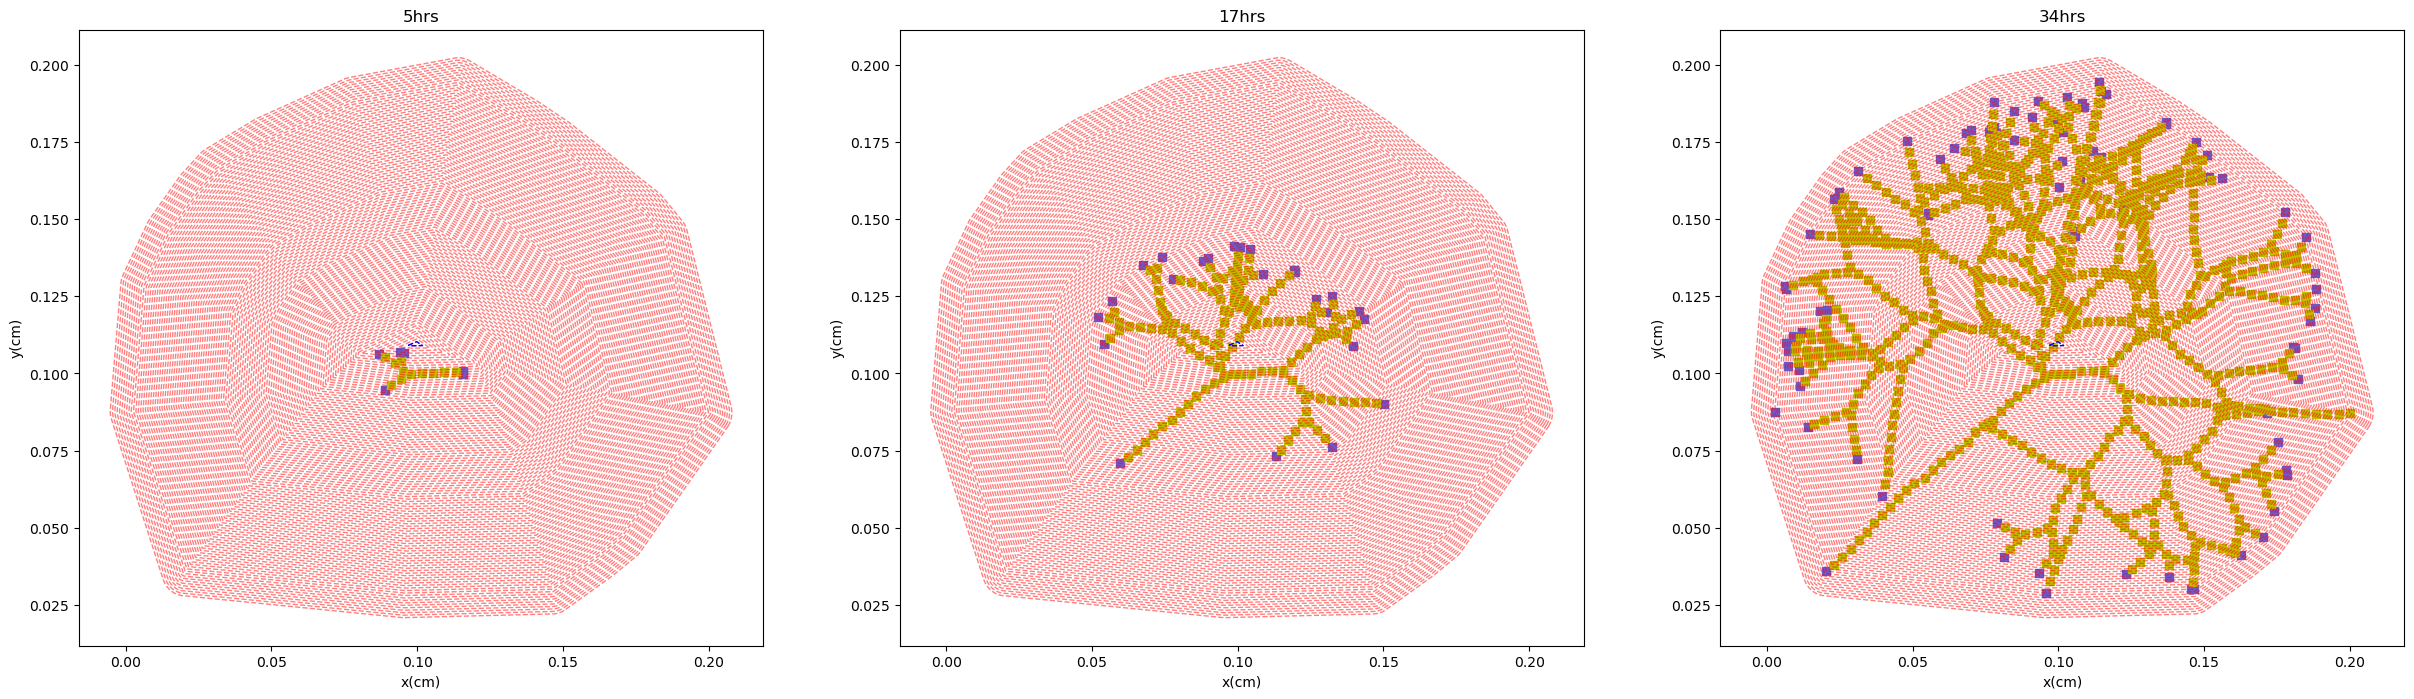

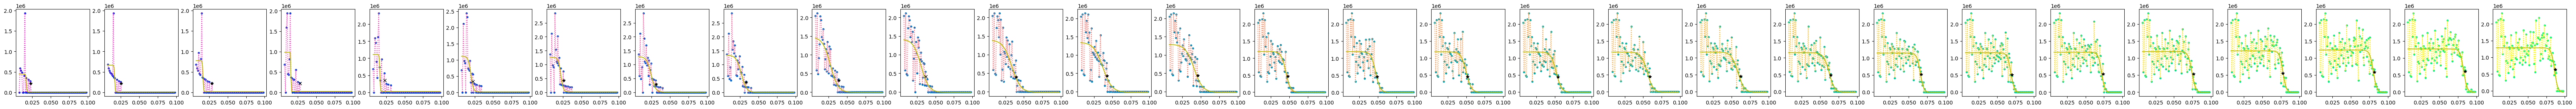

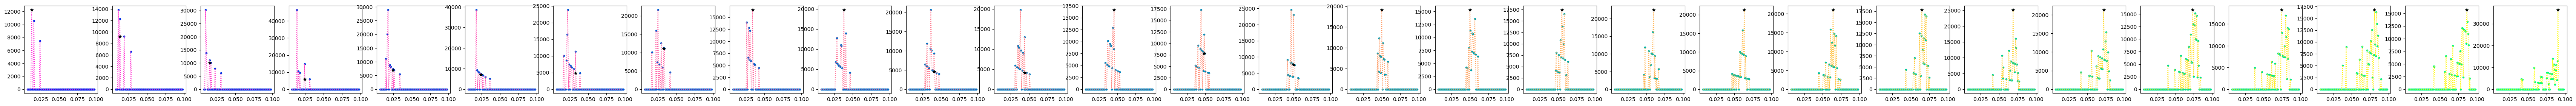

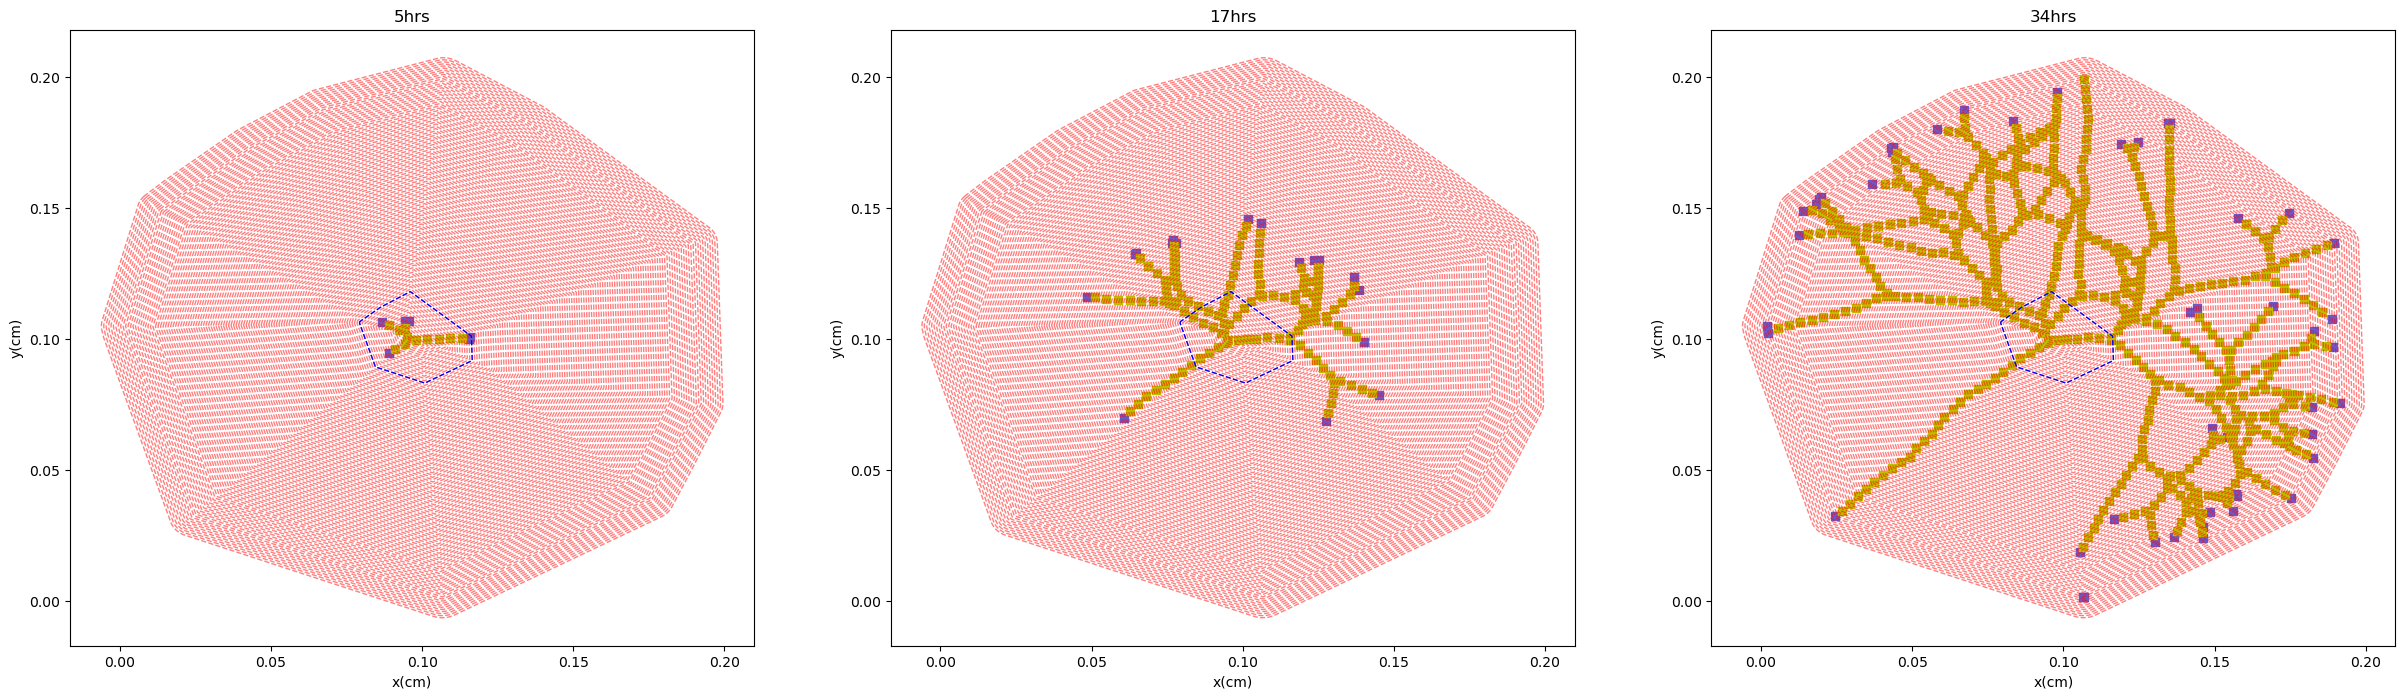

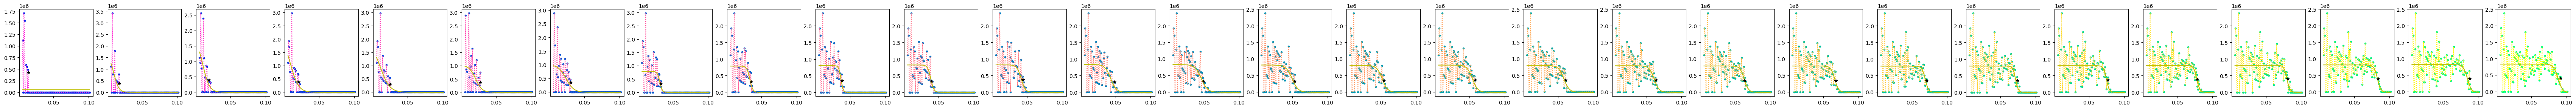

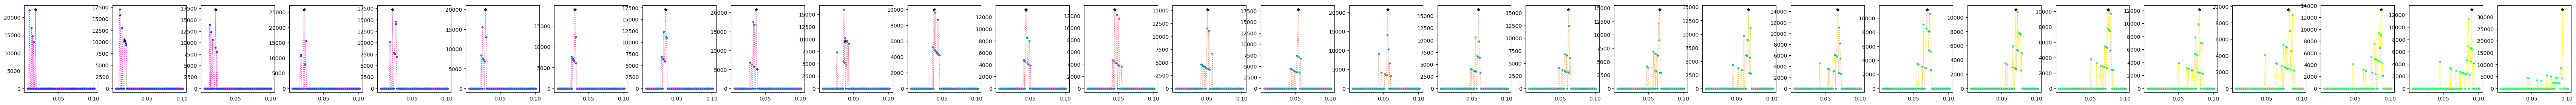

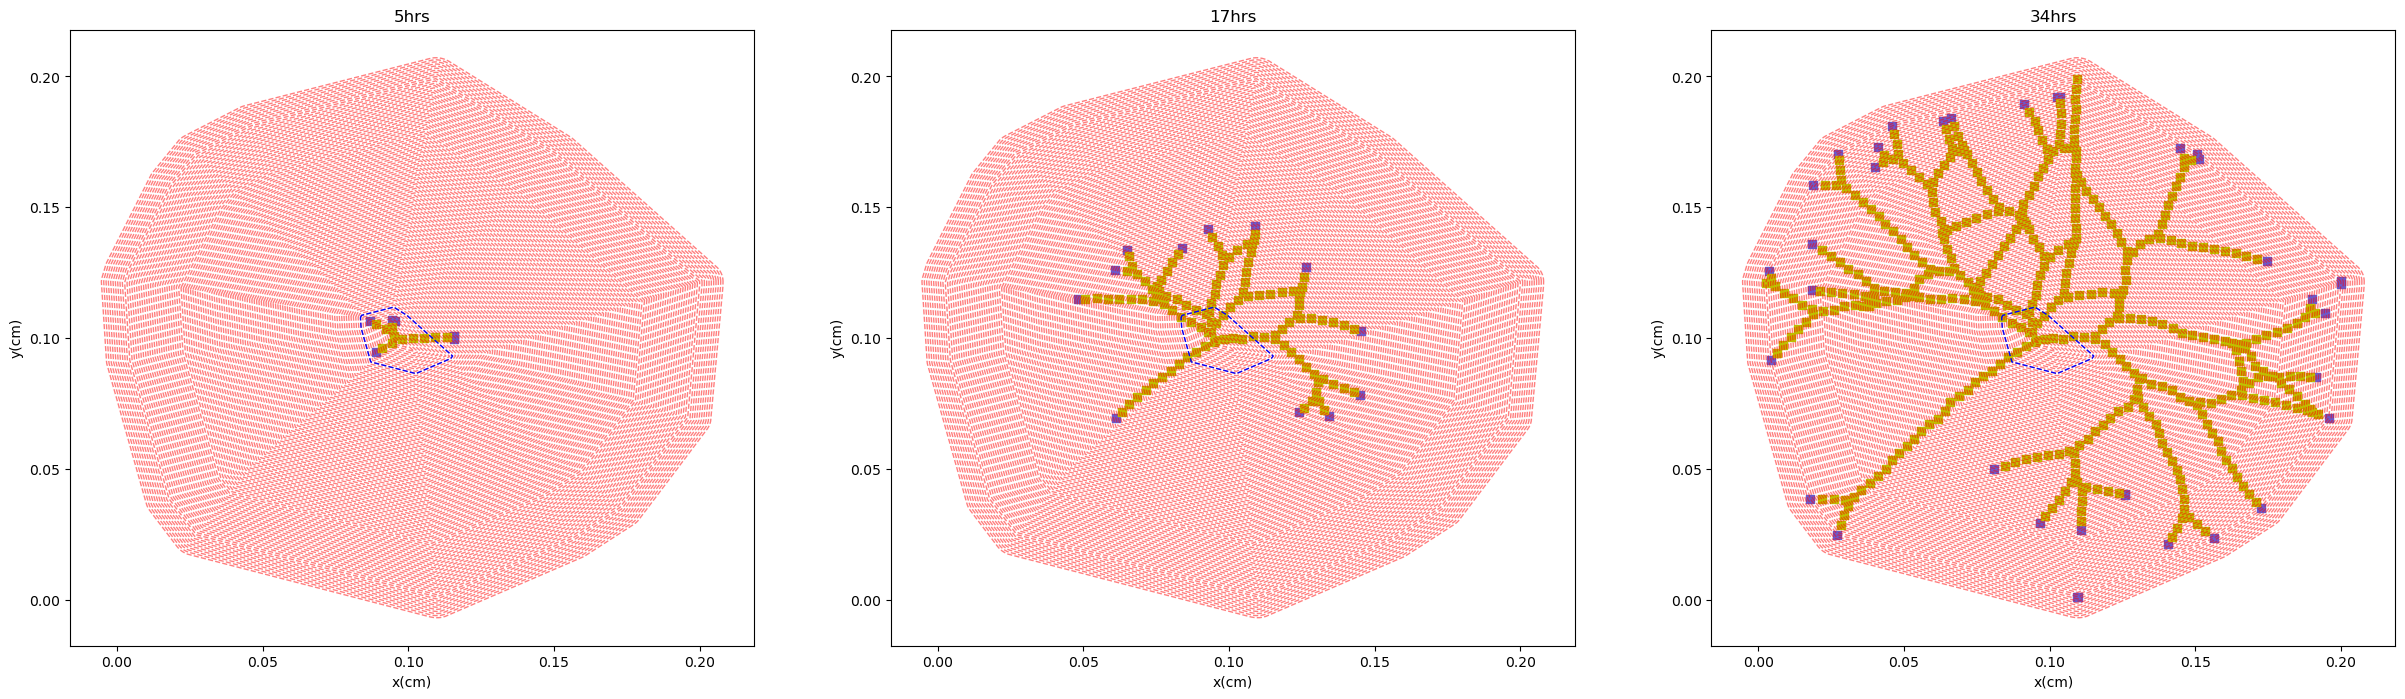

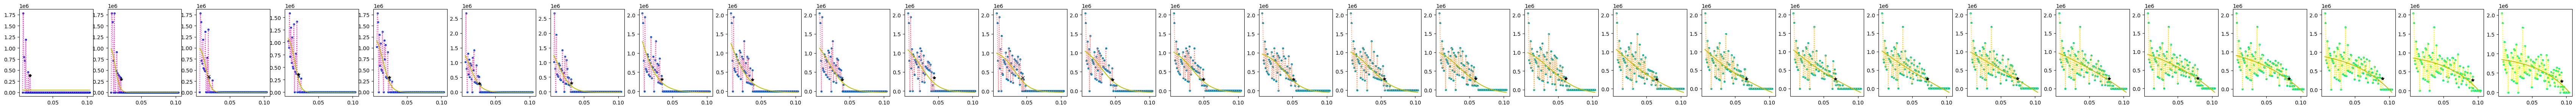

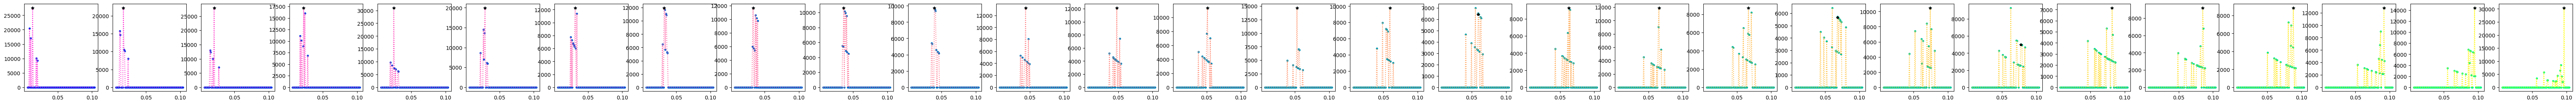

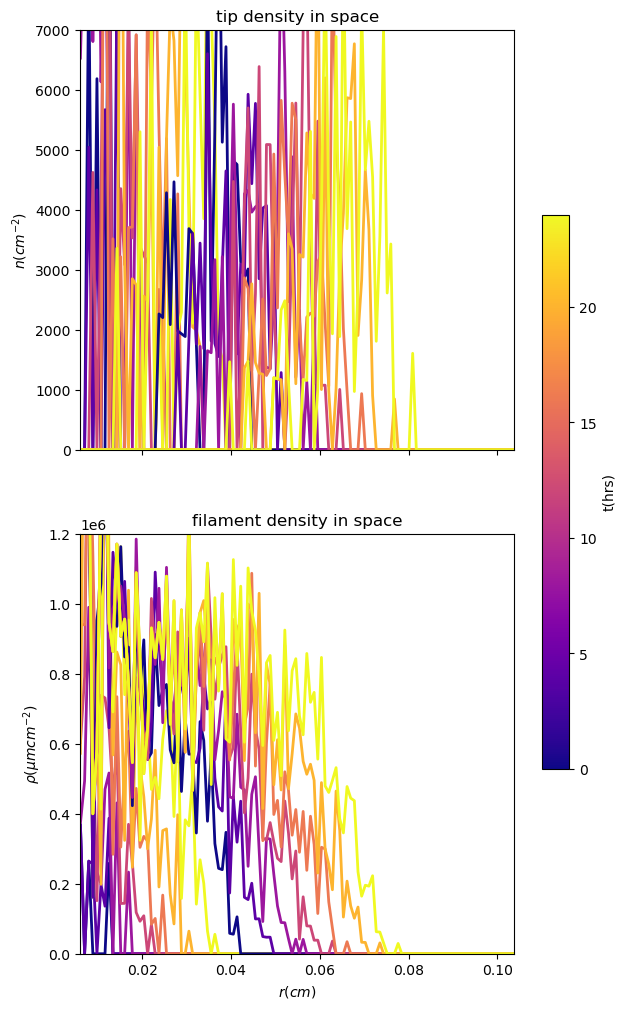

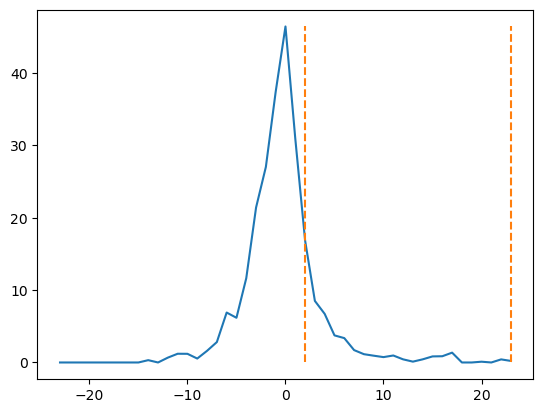

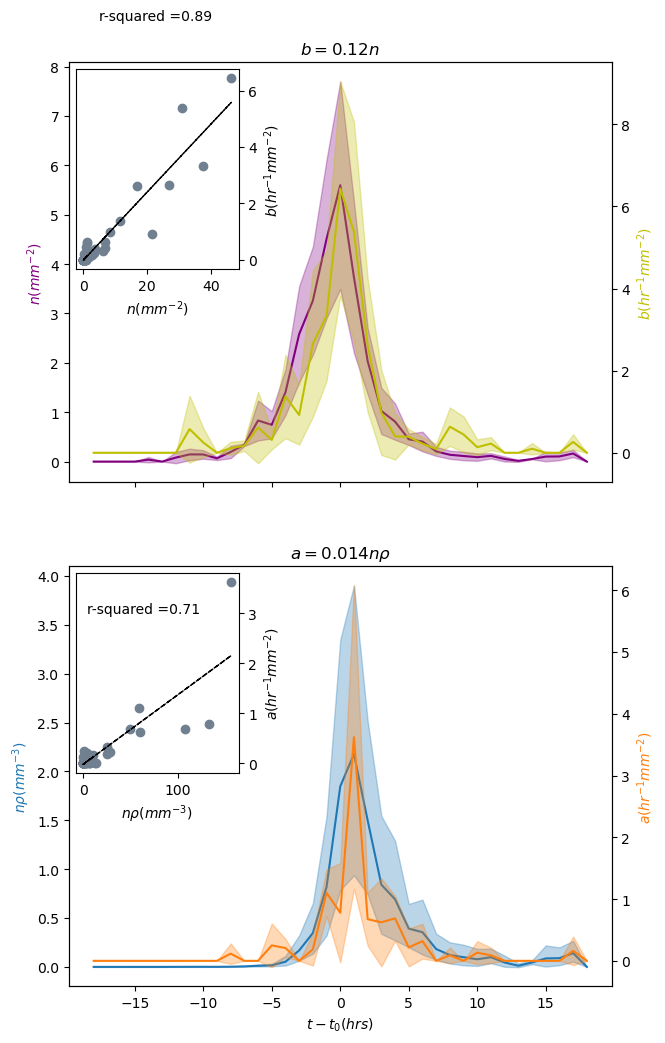

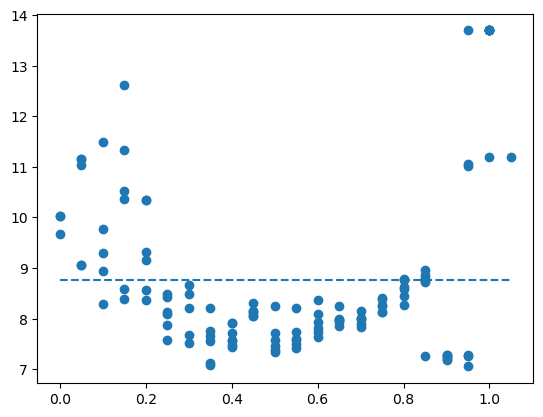

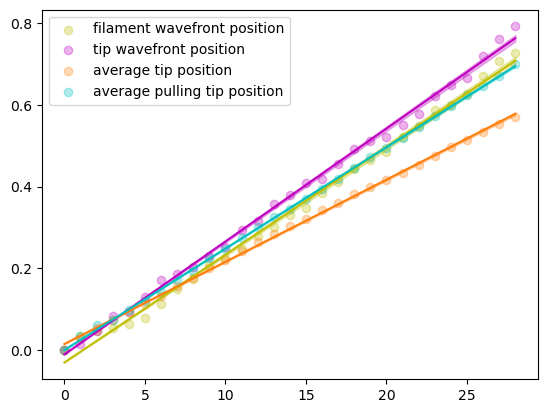

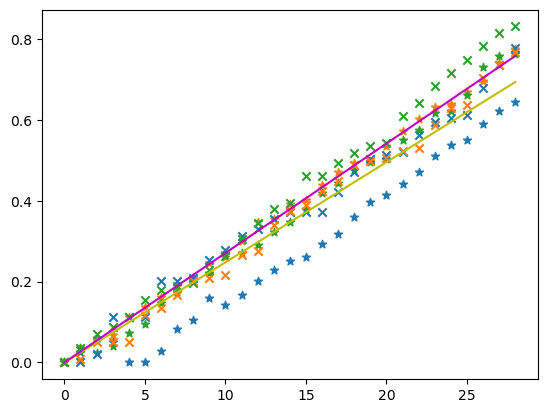

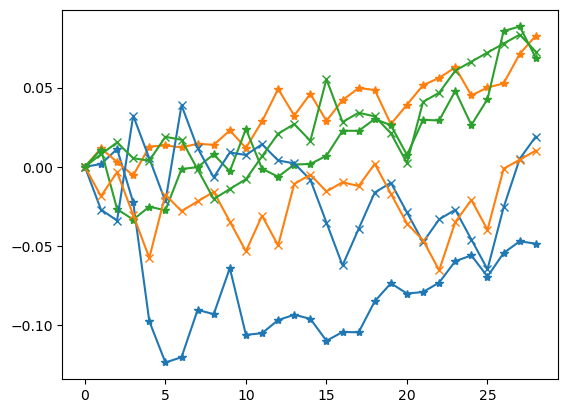

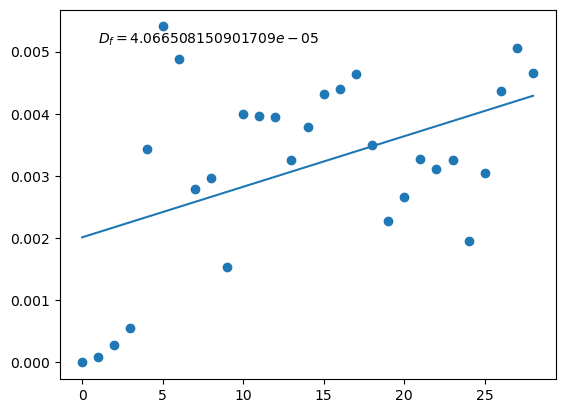

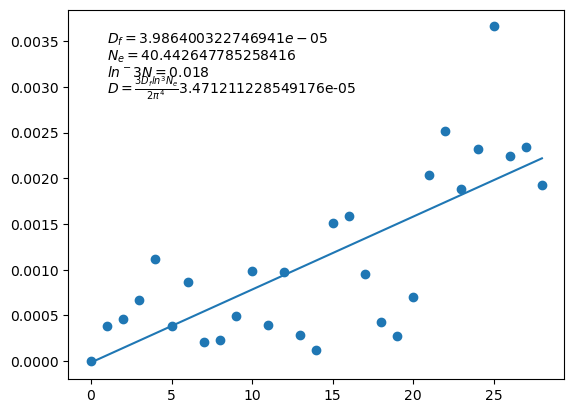

In [66]:
name = 'output_fungi_117'
n_runs = 3             
ring_width = 0.005
ABM(name, n_runs, ring_width)